# Adim 7: Model Karsilastirma ve Streaming Test

Bu notebook, egitilen 5 modeli karsilastirir ve streaming verisiyle test eder.

In [121]:
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.evaluation import RegressionEvaluator
import mlflow
import mlflow.spark
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

spark = SparkSession.builder \
    .appName("NYC-Taxi-ModelTest") \
    .config("spark.jars.packages", "io.delta:delta-spark_2.12:3.1.0") \
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension") \
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog") \
    .getOrCreate()

mlflow.set_tracking_uri("http://mlflow-server:5001")
mlflow.set_experiment("Taxi_Fare_Prediction")
print("Spark ve MLflow Hazir.")

Spark ve MLflow Hazir.


## 1. MLflow'dan Tum Modellerin Metriklerini Cekme

In [122]:
from mlflow.tracking import MlflowClient

client = MlflowClient()
experiment = client.get_experiment_by_name("Taxi_Fare_Prediction")

runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["metrics.r2 DESC"]
)

results = []
for run in runs:
    name = run.info.run_name
    metrics = run.data.metrics
    rmse = metrics.get("rmse", metrics.get("RMSE", None))
    mae = metrics.get("mae", metrics.get("MAE", None))
    r2 = metrics.get("r2", metrics.get("R2", None))
    if rmse is not None and mae is not None and r2 is not None:
        results.append({
            "Model": name,
            "Run ID": run.info.run_id,
            "RMSE": round(rmse, 4),
            "MAE": round(mae, 4),
            "R2": round(r2, 4)
        })

comparison_df = pd.DataFrame(results)
print("=" * 80)
print("MODEL KARSILASTIRMA TABLOSU")
print("=" * 80)
comparison_df

MODEL KARSILASTIRMA TABLOSU


,Model,Run ID,RMSE,MAE,R2
0,RF_Regressor_Final,4ca69d611c0247cb978b3e19b4b83661,6.9783,2.9122,0.9024
1,GBT_Regressor_Final,9090fac6e2c542958d49d6a91818e79b,7.1321,3.0066,0.8981
2,GLR_Final,ebed94f1d0aa4b1581cb09af460662f3,7.2625,3.3934,0.8943
3,Linear_Regression_Final,29c098d0b2e84cecab8593c864f07035,7.2625,3.3934,0.8943
4,Decision_Tree_Final,b6873753d99d4ba8ae2ff9ff52a0b862,7.5185,3.4502,0.8867


## 2. Metrik Karsilastirma Grafikleri

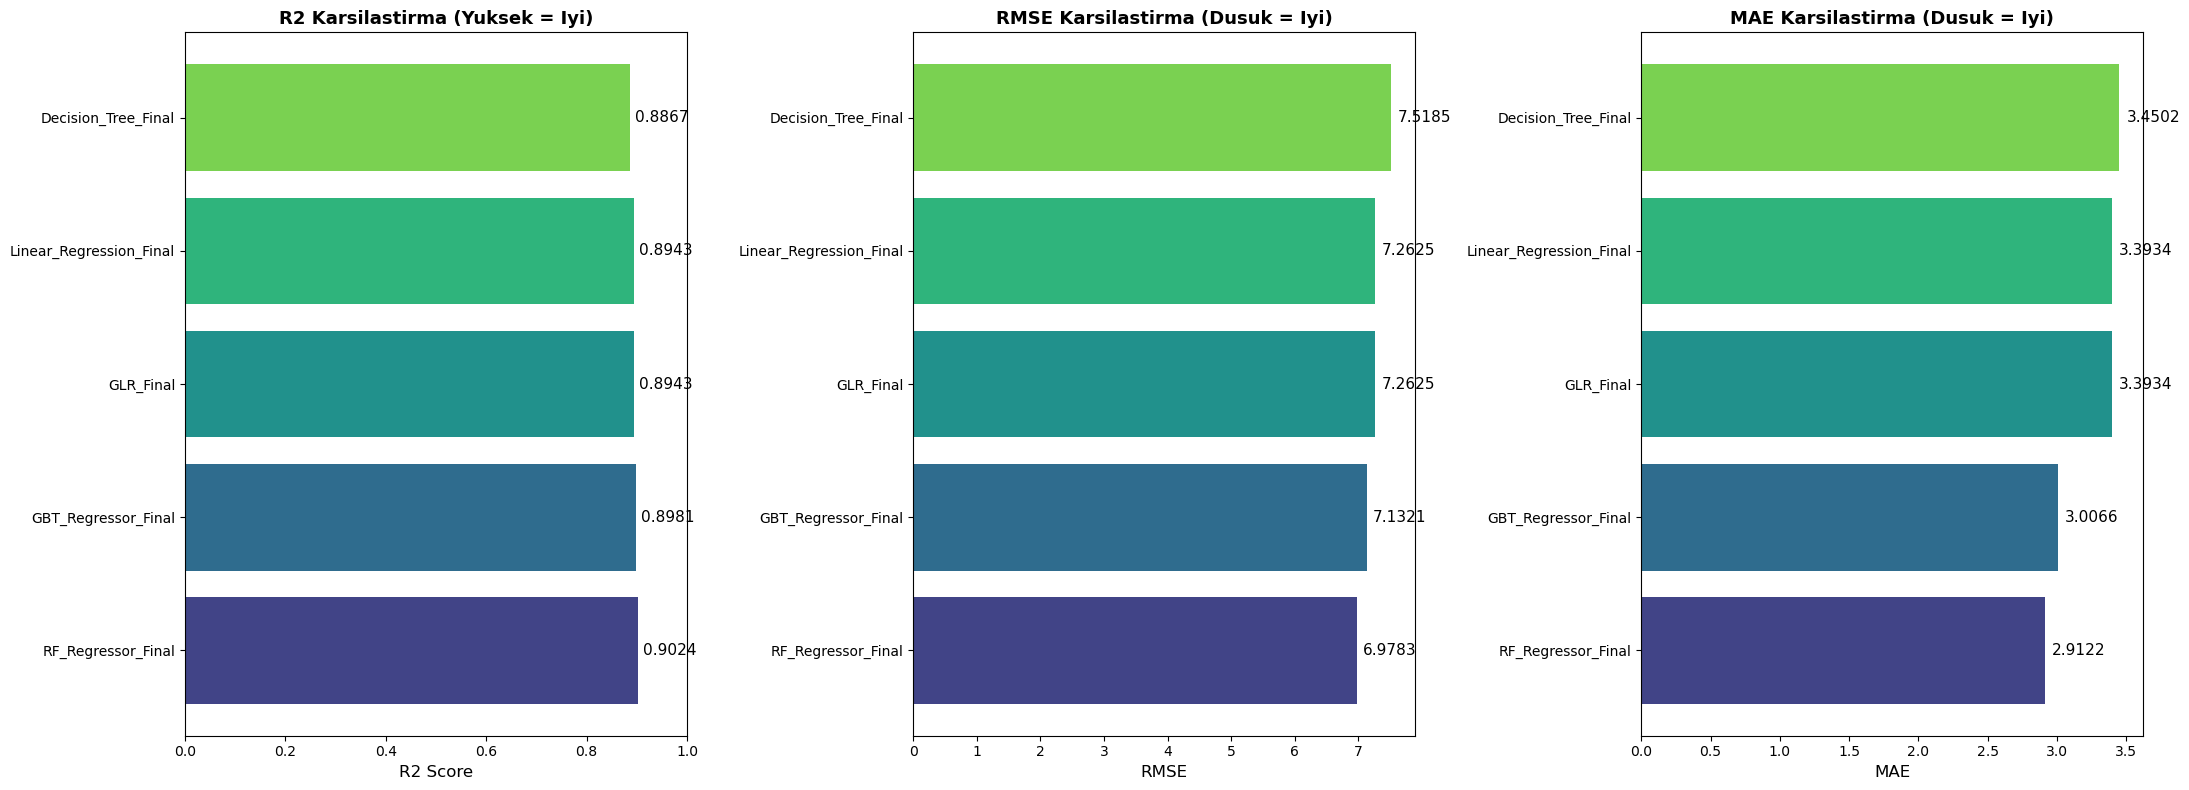

Karsilastirma grafigi kaydedildi.


In [123]:
fig, axes = plt.subplots(1, 3, figsize=(22, 8))
colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(comparison_df)))

axes[0].barh(comparison_df["Model"], comparison_df["R2"], color=colors)
axes[0].set_xlabel("R2 Score", fontsize=12)
axes[0].set_title("R2 Karsilastirma (Yuksek = Iyi)", fontsize=13, fontweight="bold")
axes[0].set_xlim(0, 1)
for i, v in enumerate(comparison_df["R2"]):
    axes[0].text(v + 0.01, i, str(round(v, 4)), va="center", fontsize=11)

axes[1].barh(comparison_df["Model"], comparison_df["RMSE"], color=colors)
axes[1].set_xlabel("RMSE", fontsize=12)
axes[1].set_title("RMSE Karsilastirma (Dusuk = Iyi)", fontsize=13, fontweight="bold")
for i, v in enumerate(comparison_df["RMSE"]):
    axes[1].text(v + 0.1, i, str(round(v, 4)), va="center", fontsize=11)

axes[2].barh(comparison_df["Model"], comparison_df["MAE"], color=colors)
axes[2].set_xlabel("MAE", fontsize=12)
axes[2].set_title("MAE Karsilastirma (Dusuk = Iyi)", fontsize=13, fontweight="bold")
for i, v in enumerate(comparison_df["MAE"]):
    axes[2].text(v + 0.05, i, str(round(v, 4)), va="center", fontsize=11)

plt.tight_layout()
plt.savefig("/home/jovyan/work/data/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Karsilastirma grafigi kaydedildi.")

## 3. Streaming Verisini Yukleme ve Hazirlama

In [124]:
from pyspark.sql.functions import col, unix_timestamp, hour, dayofweek, when, lit

stream_path = "/home/jovyan/work/data/delta/taxi_trips/stream_silver"
stream_df = spark.read.format("delta").load(stream_path)

print("Stream Silver kayit sayisi: " + str(stream_df.count()))
stream_df.printSchema()

# Son 5 kaydi goster
last5 = spark.createDataFrame(stream_df.tail(5), stream_df.schema)
last5.show(truncate=False)

Stream Silver kayit sayisi: 351865
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: double (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: double (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- kafka_timestamp: timestamp (nullable = true)

+--------+--------------------+----------

## 4. Feature Engineering (Streaming Verisi Icin)

In [125]:
# Streaming verisi icin feature olustur
# Gold tablosundaki ayni feature'lari olusturuyoruz
stream_features = stream_df

# Gerekli sutunlarin varligini kontrol et, yoksa olustur
existing_cols = [c.lower() for c in stream_features.columns]

if "trip_duration_min" not in existing_cols:
    stream_features = stream_features.withColumn("trip_duration_min",
        (unix_timestamp("tpep_dropoff_datetime") - unix_timestamp("tpep_pickup_datetime")) / 60)

if "average_speed" not in existing_cols:
    stream_features = stream_features.withColumn("average_speed",
        col("trip_distance") / (col("trip_duration_min") / 60))

if "pickup_hour" not in existing_cols:
    stream_features = stream_features.withColumn("pickup_hour", hour("tpep_pickup_datetime"))

if "day_of_week" not in existing_cols:
    stream_features = stream_features.withColumn("day_of_week", dayofweek("tpep_pickup_datetime"))

if "is_airport_trip" not in existing_cols:
    stream_features = stream_features.withColumn("is_airport_trip",
        when((col("PULocationID") == 132) | (col("PULocationID") == 138), 1).otherwise(0))

if "is_rush_hour" not in existing_cols:
    stream_features = stream_features.withColumn("is_rush_hour",
        when(((col("pickup_hour") >= 7) & (col("pickup_hour") <= 9)) |
             ((col("pickup_hour") >= 17) & (col("pickup_hour") <= 19)), 1).otherwise(0))

# Filtrele
stream_features = stream_features.filter(
    (col("trip_distance") > 0.5) &
    (col("total_amount") > 2.5) &
    (col("total_amount") < 150) &
    (col("trip_duration_min") > 1) &
    (col("trip_duration_min") < 120)
)

# Feature vector
feature_cols = ["trip_distance", "trip_duration_min", "average_speed",
                "pickup_hour", "day_of_week", "is_airport_trip", "is_rush_hour"]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
test_df = assembler.transform(stream_features).select("features", "total_amount")

print(f"Test seti (streaming): {test_df.count()} kayit")

Test seti (streaming): 333252 kayit


## 5. Tum Modelleri Streaming Verisi Uzerinde Test Et

In [126]:
evaluator_rmse = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="rmse")
evaluator_mae = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="mae")
evaluator_r2 = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="r2")

stream_results = []
model_predictions = {}

for _, row in comparison_df.iterrows():
    model_name = row["Model"]
    run_id = row["Run ID"]
    
    print("Model yukleniyor: " + model_name)
    
    try:
        model_uri = "runs:/" + run_id
        artifacts = client.list_artifacts(run_id)
        model_artifact = None
        for art in artifacts:
            if art.is_dir and "model" in art.path.lower():
                model_artifact = art.path
                break
        
        if model_artifact is None:
            print("  Model artifact bulunamadi, atlaniyor.")
            continue
        
        loaded_model = mlflow.spark.load_model(model_uri + "/" + model_artifact)
        
        predictions = loaded_model.transform(test_df)
        
        rmse = evaluator_rmse.evaluate(predictions)
        mae = evaluator_mae.evaluate(predictions)
        r2 = evaluator_r2.evaluate(predictions)
        
        stream_results.append({
            "Model": model_name,
            "Stream RMSE": round(rmse, 4),
            "Stream MAE": round(mae, 4),
            "Stream R2": round(r2, 4)
        })
        
        sample = predictions.select("total_amount", "prediction").sample(0.1).toPandas()
        model_predictions[model_name] = sample
        
        print("  RMSE=" + str(round(rmse, 4)) + ", MAE=" + str(round(mae, 4)) + ", R2=" + str(round(r2, 4)))
        
    except Exception as e:
        print("  Hata: " + str(e))

stream_comparison = pd.DataFrame(stream_results)
print()
print("=" * 80)
print("STREAMING VERISI UZERINDE MODEL SONUCLARI")
print("=" * 80)
stream_comparison

Model yukleniyor: RF_Regressor_Final


2026/05/08 13:25:14 INFO mlflow.spark: URI 'runs:/4ca69d611c0247cb978b3e19b4b83661/rf_model/sparkml' does not point to the current DFS.
2026/05/08 13:25:14 INFO mlflow.spark: File 'runs:/4ca69d611c0247cb978b3e19b4b83661/rf_model/sparkml' not found on DFS. Will attempt to upload the file.


  RMSE=5.5378, MAE=2.7777, R2=0.9221
Model yukleniyor: GBT_Regressor_Final


2026/05/08 13:25:19 INFO mlflow.spark: URI 'runs:/9090fac6e2c542958d49d6a91818e79b/gbt_model/sparkml' does not point to the current DFS.
2026/05/08 13:25:19 INFO mlflow.spark: File 'runs:/9090fac6e2c542958d49d6a91818e79b/gbt_model/sparkml' not found on DFS. Will attempt to upload the file.


  RMSE=5.7965, MAE=2.9111, R2=0.9147
Model yukleniyor: GLR_Final


2026/05/08 13:25:23 INFO mlflow.spark: URI 'runs:/ebed94f1d0aa4b1581cb09af460662f3/glr_model/sparkml' does not point to the current DFS.
2026/05/08 13:25:23 INFO mlflow.spark: File 'runs:/ebed94f1d0aa4b1581cb09af460662f3/glr_model/sparkml' not found on DFS. Will attempt to upload the file.


... (2 outputs left out)

  RMSE=6.4268, MAE=3.4237, R2=0.8951
Model yukleniyor: Decision_Tree_Final


2026/05/08 13:25:30 INFO mlflow.spark: URI 'runs:/b6873753d99d4ba8ae2ff9ff52a0b862/dt_model/sparkml' does not point to the current DFS.
2026/05/08 13:25:30 INFO mlflow.spark: File 'runs:/b6873753d99d4ba8ae2ff9ff52a0b862/dt_model/sparkml' not found on DFS. Will attempt to upload the file.


  RMSE=6.1565, MAE=3.373, R2=0.9038

STREAMING VERISI UZERINDE MODEL SONUCLARI


,Model,Stream RMSE,Stream MAE,Stream R2
0,RF_Regressor_Final,5.5378,2.7777,0.9221
1,GBT_Regressor_Final,5.7965,2.9111,0.9147
2,GLR_Final,6.4268,3.4237,0.8951
3,Linear_Regression_Final,6.4268,3.4237,0.8951
4,Decision_Tree_Final,6.1565,3.3730,0.9038


## 6. Gercek vs Tahmin Grafikleri (Her Model Icin)

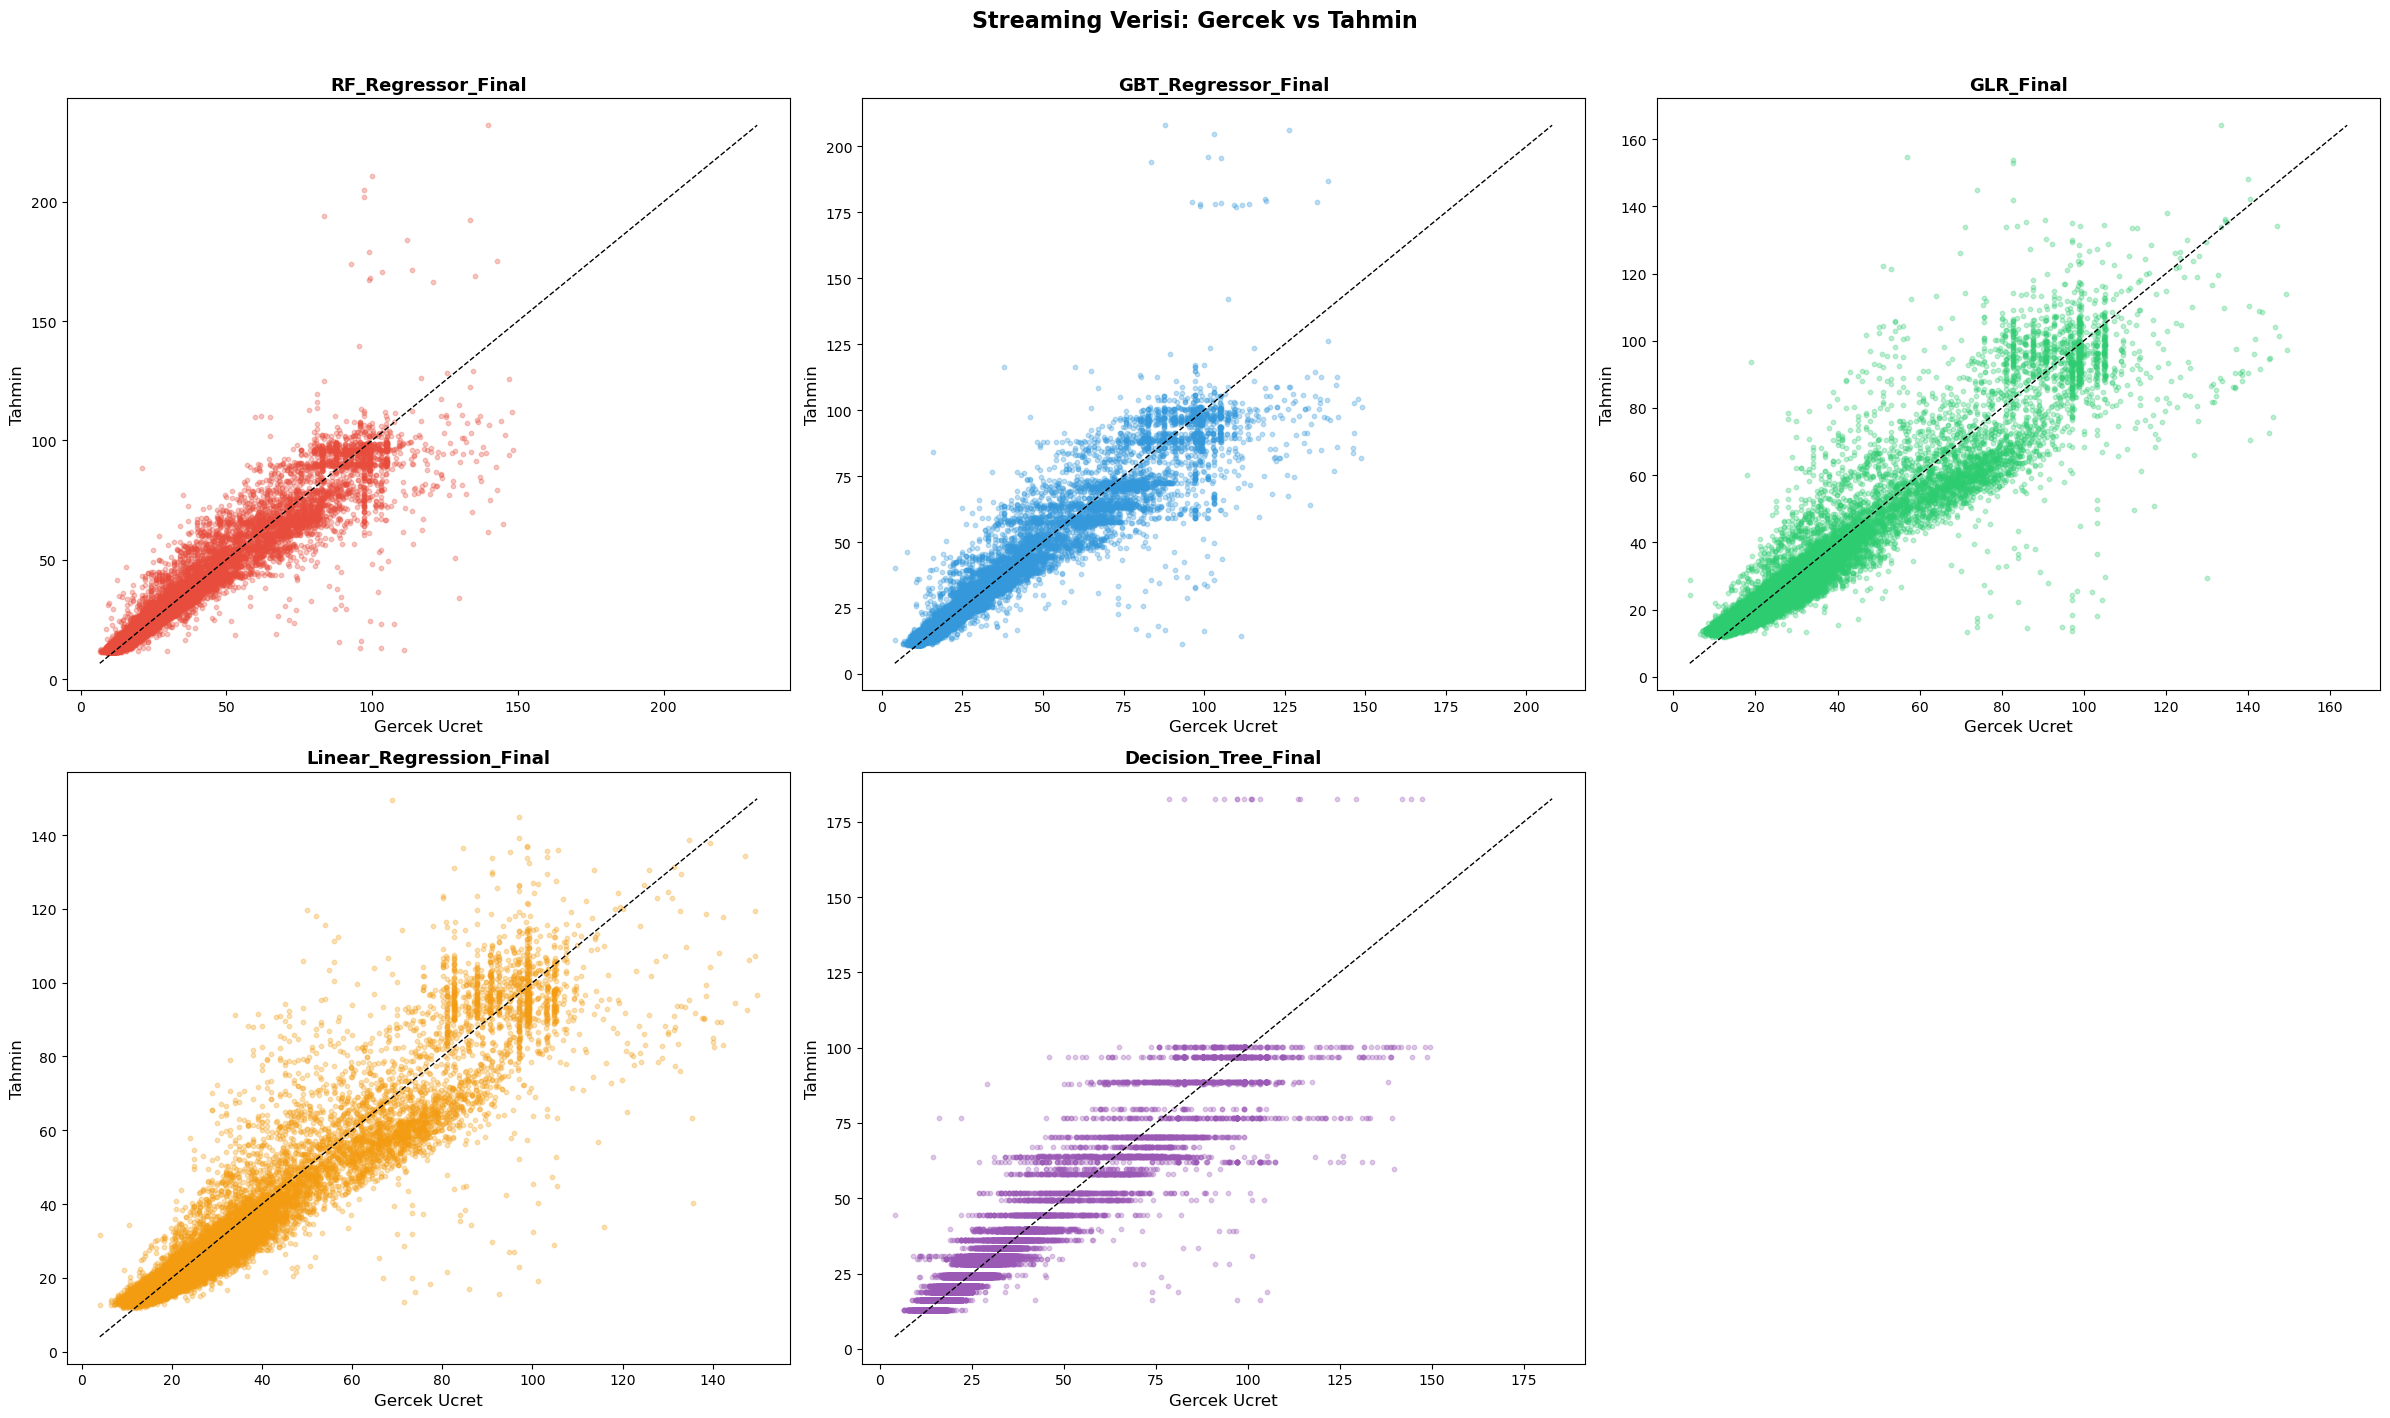

In [127]:
import math

n_models = len(model_predictions)
if n_models > 0:
    ncols = 3
    nrows = math.ceil(n_models / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(8 * ncols, 7 * nrows))
    axes = axes.flatten() if n_models > 1 else [axes]
    
    colors = ["#e74c3c", "#3498db", "#2ecc71", "#f39c12", "#9b59b6"]
    
    for idx, (name, preds) in enumerate(model_predictions.items()):
        ax = axes[idx]
        c = colors[idx % len(colors)]
        ax.scatter(preds["total_amount"], preds["prediction"], alpha=0.3, s=10, color=c)
        mn = min(preds["total_amount"].min(), preds["prediction"].min())
        mx = max(preds["total_amount"].max(), preds["prediction"].max())
        ax.plot([mn, mx], [mn, mx], "k--", lw=1)
        ax.set_xlabel("Gercek Ucret", fontsize=12)
        ax.set_ylabel("Tahmin", fontsize=12)
        ax.set_title(name, fontsize=13, fontweight="bold")
    
    for idx in range(n_models, len(axes)):
        axes[idx].set_visible(False)
    
    plt.suptitle("Streaming Verisi: Gercek vs Tahmin", fontsize=16, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig("/home/jovyan/work/data/stream_predictions.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Gosterilecek tahmin yok.")

## 7. Hata Dagilimi Karsilastirmasi

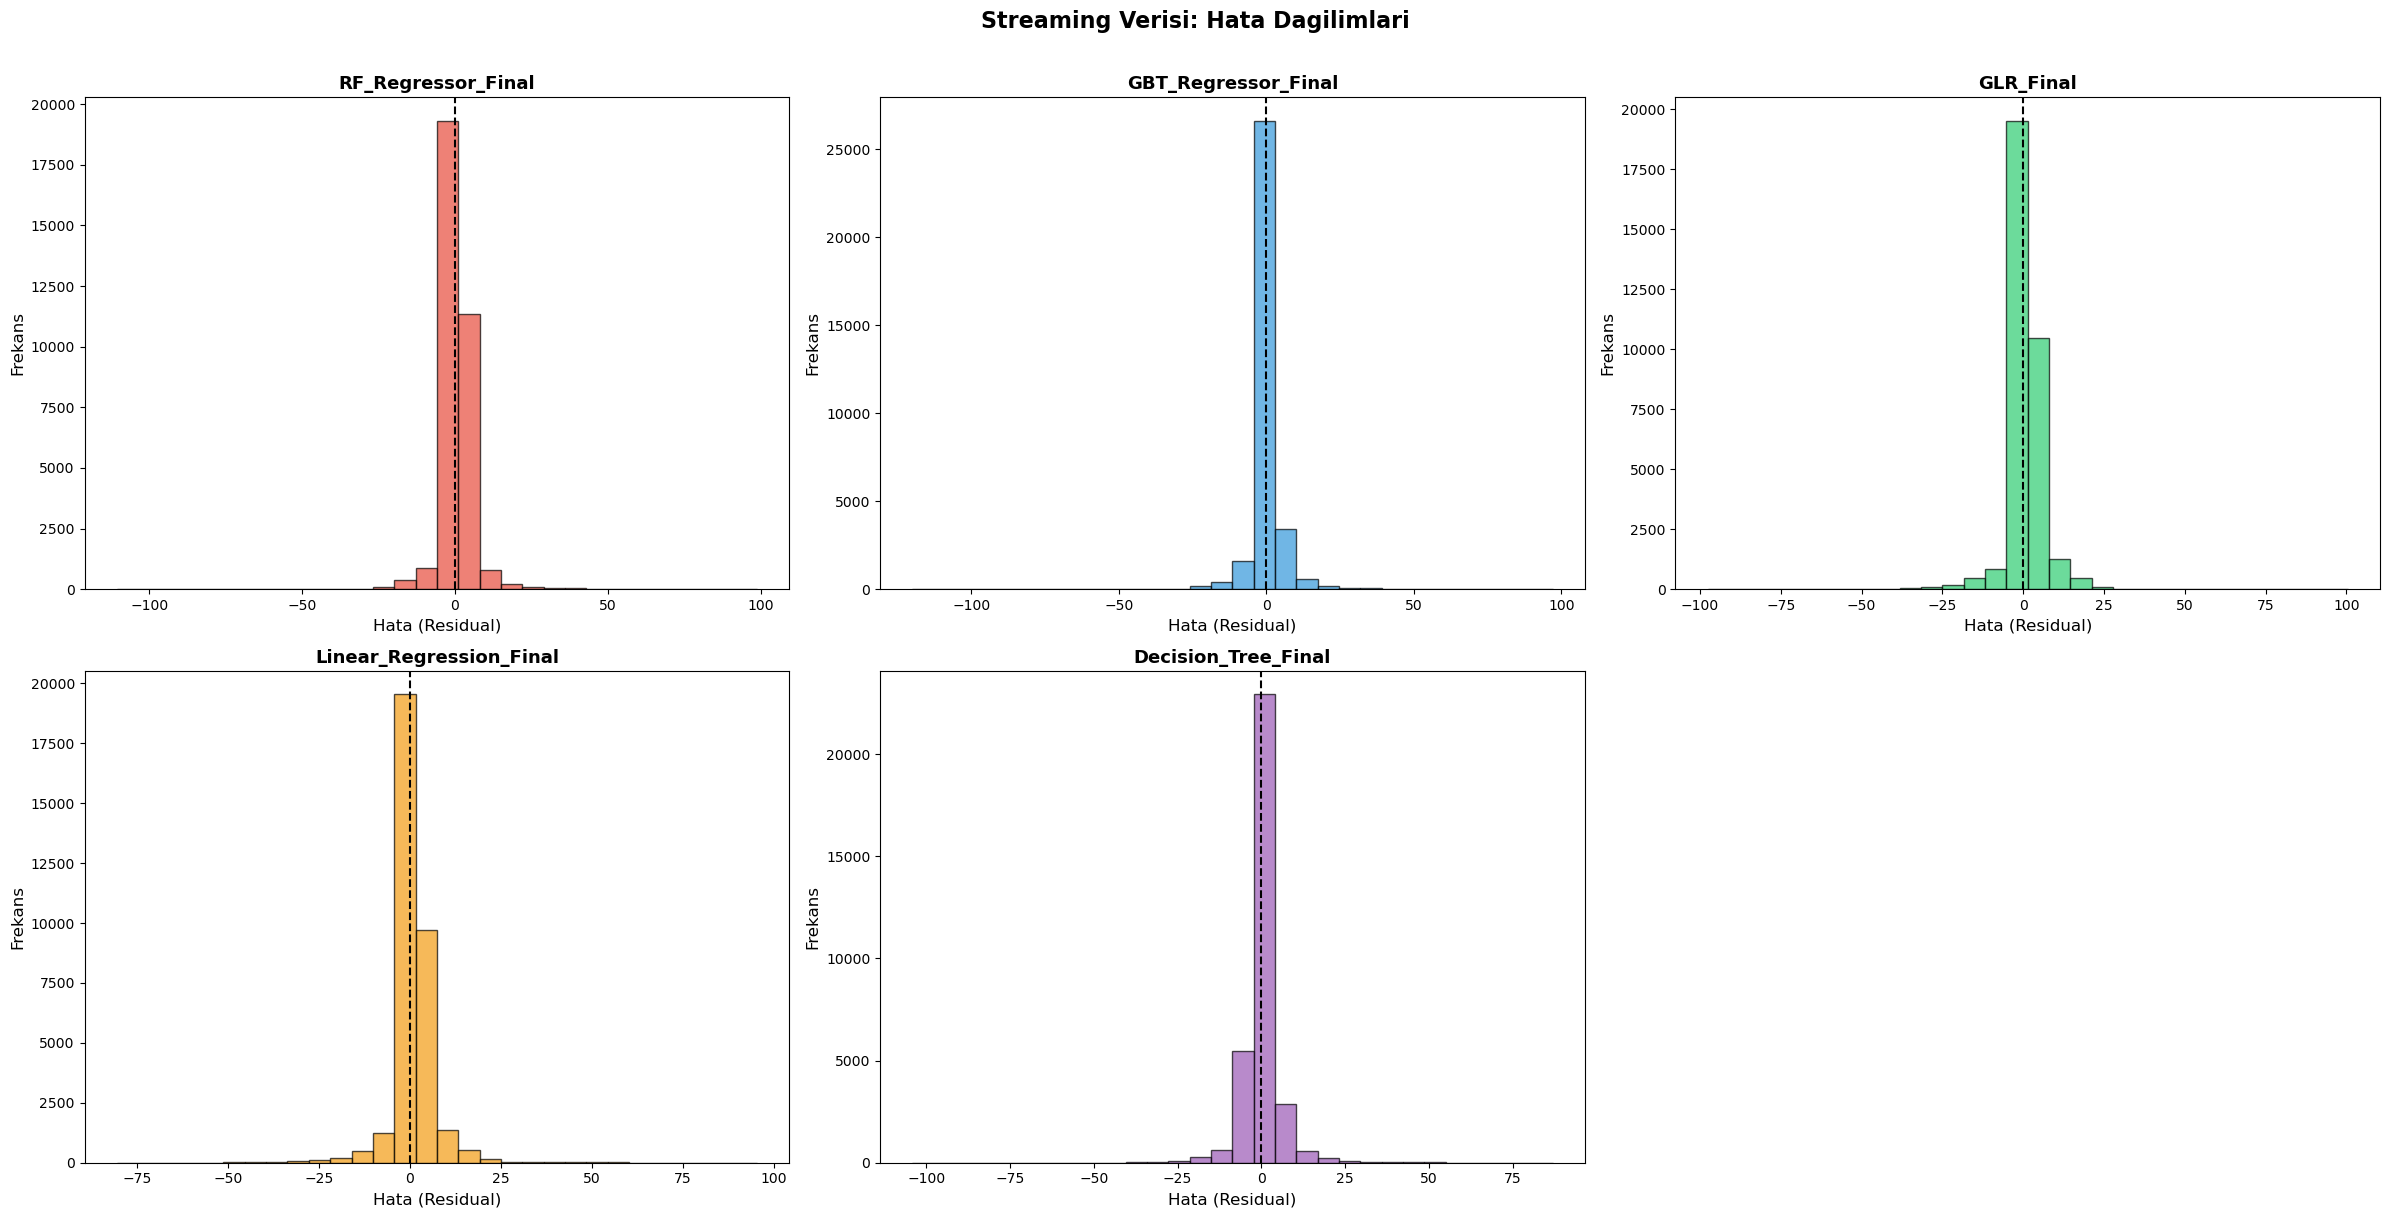

In [128]:
if len(model_predictions) > 0:
    n = len(model_predictions)
    ncols = 3
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(8 * ncols, 6 * nrows))
    axes = axes.flatten() if n > 1 else [axes]
    
    colors = ["#e74c3c", "#3498db", "#2ecc71", "#f39c12", "#9b59b6"]
    
    for idx, (name, preds) in enumerate(model_predictions.items()):
        ax = axes[idx]
        residuals = preds["total_amount"] - preds["prediction"]
        ax.hist(residuals, bins=30, color=colors[idx % len(colors)], alpha=0.7, edgecolor="black")
        ax.axvline(x=0, color="black", linestyle="--")
        ax.set_xlabel("Hata (Residual)", fontsize=12)
        ax.set_ylabel("Frekans", fontsize=12)
        ax.set_title(name, fontsize=13, fontweight="bold")
    
    for idx in range(n, len(axes)):
        axes[idx].set_visible(False)
    
    plt.suptitle("Streaming Verisi: Hata Dagilimlari", fontsize=16, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig("/home/jovyan/work/data/stream_residuals.png", dpi=150, bbox_inches="tight")
    plt.show()

## 8. En Iyi Model Ozeti

In [129]:
if len(stream_results) > 0:
    best = max(stream_results, key=lambda x: x["Stream R2"])
    print("=" * 60)
    print("EN IYI MODEL: " + best["Model"])
    print("  R2:   " + str(best["Stream R2"]))
    print("  RMSE: " + str(best["Stream RMSE"]))
    print("  MAE:  " + str(best["Stream MAE"]))
    print("=" * 60)
else:
    print("Sonuc yok.")

EN IYI MODEL: RF_Regressor_Final
  R2:   0.9221
  RMSE: 5.5378
  MAE:  2.7777
